# Diagnosing weak instrumental variables

This native Julia companion preserves the declared graphs, causal targets, generating equations, parameters, original seeds, sample sizes, repetitions and decision rules. Fixed primitive NumPy streams reproduce the original experiments; Julia generates all observations and computes all estimates and diagnostics. Native exception types check the same rejection conditions. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

A valid instrument changes treatment, affects outcome only through treatment, and is independent of the unmeasured causes of the outcome:

$$
\operatorname{Cov}(Z,X)\neq0,
\qquad
Y(x,z)=Y(x),
\qquad
Z\mathbin{\perp\!\!\!\perp}\{Y(x),X(z)\}.
$$

Here, $Z$ is the instrument, $X$ is treatment, $Y$ is outcome, $Y(x,z)$ is the potential outcome under treatment $x$ and instrument $z$, $Y(x)$ records the exclusion restriction, and $X(z)$ is the potential treatment under instrument value $z$. The first condition is relevance; the last two require substantive design arguments.

Row,Condition,Question,Observable implication,Enough by itself
,String,String,String,String
1,Relevance,Does the instrument move treatment?,Nonzero first-stage relation,No
2,Exclusion,Does the instrument avoid a direct outcome path?,Not established by relevance,No
3,Outside variation,Is the instrument separated from unmeasured outcome causes?,Needs a design argument,No


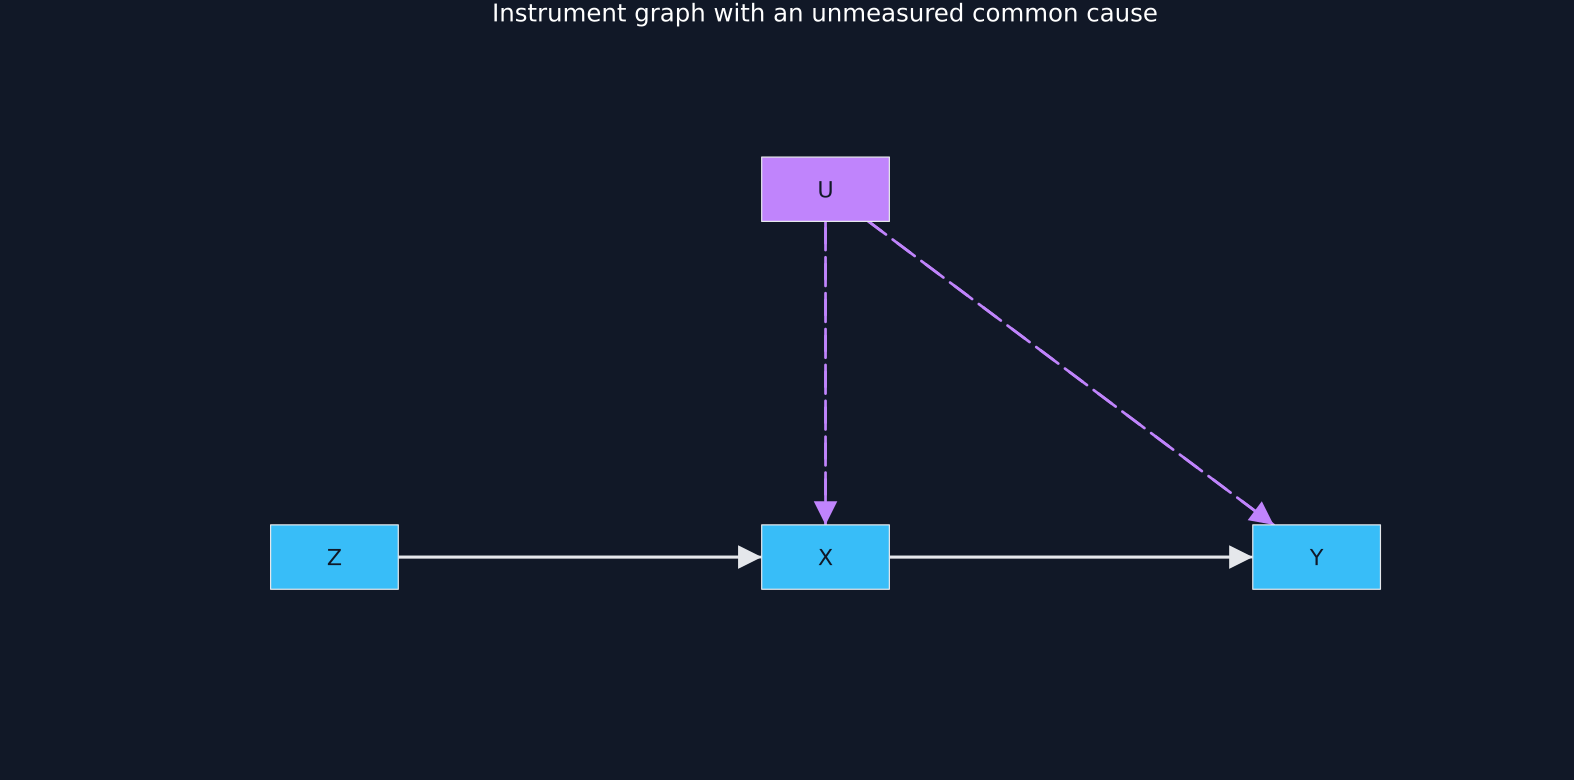

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("02_graphical_identification");
using CSV, TOML
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
using RiskLabAI.CausalFactorAnalysis: d_separation
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
input_directory = joinpath("..","data","chapter02_random_inputs")
table(values,name,caption) = save_table(values,paths,name;caption,label="tab:chapter24-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy
function table(values,name,caption)
    shown = copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column] = ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter24-"*replace(name,"_"=>"-"))
    return nothing
end
store = PrimitiveStore(input_directory,"iv")
iv_graph = DirectedGraph([("Z","X"),("X","Y"),("U","X"),("U","Y")])
positions = Dict("Z"=>(0.,0.),"X"=>(1.5,0.),"Y"=>(3.,0.),"U"=>(1.5,1.2))
iv_conditions = frame(["Condition","Question","Observable implication","Enough by itself"],[["Relevance","Does the instrument move treatment?","Nonzero first-stage relation",false],["Exclusion","Does the instrument avoid a direct outcome path?","Not established by relevance",false],["Outside variation","Is the instrument separated from unmeasured outcome causes?","Needs a design argument",false]])
table(iv_conditions,"iv_conditions","Three distinct requirements for an instrument.")
save_figure(plot(identification_graph_panel(iv_graph,positions,"Instrument graph with an unmeasured common cause";latent=["U"]);size=(1050,520)),paths,"iv_graph")


## Relating estimate stability to instrument strength

With one instrument and an intercept, the instrumental-variable point estimate is a ratio of sample covariances:

$$
\widehat\beta_{\mathrm{IV}}
=\frac{\widehat{\operatorname{Cov}}(Z,Y)}{\widehat{\operatorname{Cov}}(Z,X)}.
$$

Here, $\widehat\beta_{\mathrm{IV}}$ is the just-identified effect estimate, $Z$ is the instrument, $X$ is treatment, $Y$ is outcome, and the denominator measures how strongly the instrument moves treatment.

The first-stage strength statistic for one excluded instrument is the squared fitted instrument coefficient divided by its estimated variance:

$$
F=\frac{\widehat\pi^2}{\widehat{\operatorname{Var}}(\widehat\pi)},
\qquad
X=\alpha_X+\pi Z+v.
$$

Here, $F$ is the first-stage statistic, $\widehat\pi$ is the fitted instrument coefficient, $\widehat{\operatorname{Var}}(\widehat\pi)$ is its estimated variance, $\alpha_X$ is an intercept, and $v$ is the first-stage residual. The value 10 is used below as a practical warning line, not as proof of validity.

The generated panel fixes the causal effect while changing only instrument relevance and confounding strength:

$$
X=\pi Z+\phi U+\varepsilon_X,
\qquad
Y=\beta X+\gamma U+\varepsilon_Y,
\qquad
W=U+\kappa\varepsilon_W.
$$

Here, $U$ is the unmeasured common cause, $Z$ is the instrument, $W$ is a noisy proxy for the common cause, $\beta$ is the known treatment effect, $\pi$ is instrument relevance, $\phi$ and $\gamma$ are the common-cause loadings, $\kappa$ controls proxy noise, and the three $\varepsilon$ terms are independent standard-normal shocks.

Row,Parameter,Symbol,Value
,String,String,Real
1,Known treatment effect,beta,0.5
2,Common-cause loading on treatment,phi,1.0
3,Observations in released example,n,3000
4,Strong-warning line,F,10
5,Confidence level,one minus alpha,0.95


Row,Instrument relevance,First-stage F,Ordinary estimate,Instrumental estimate,Robust set kind
,Float64,Float64,Float64,Float64,String
1,0.6,528.723,0.910294,0.47274,interval
2,0.12,8.58758,1.02131,0.137811,interval
3,0.04,2.41454,1.03359,0.686781,allreal


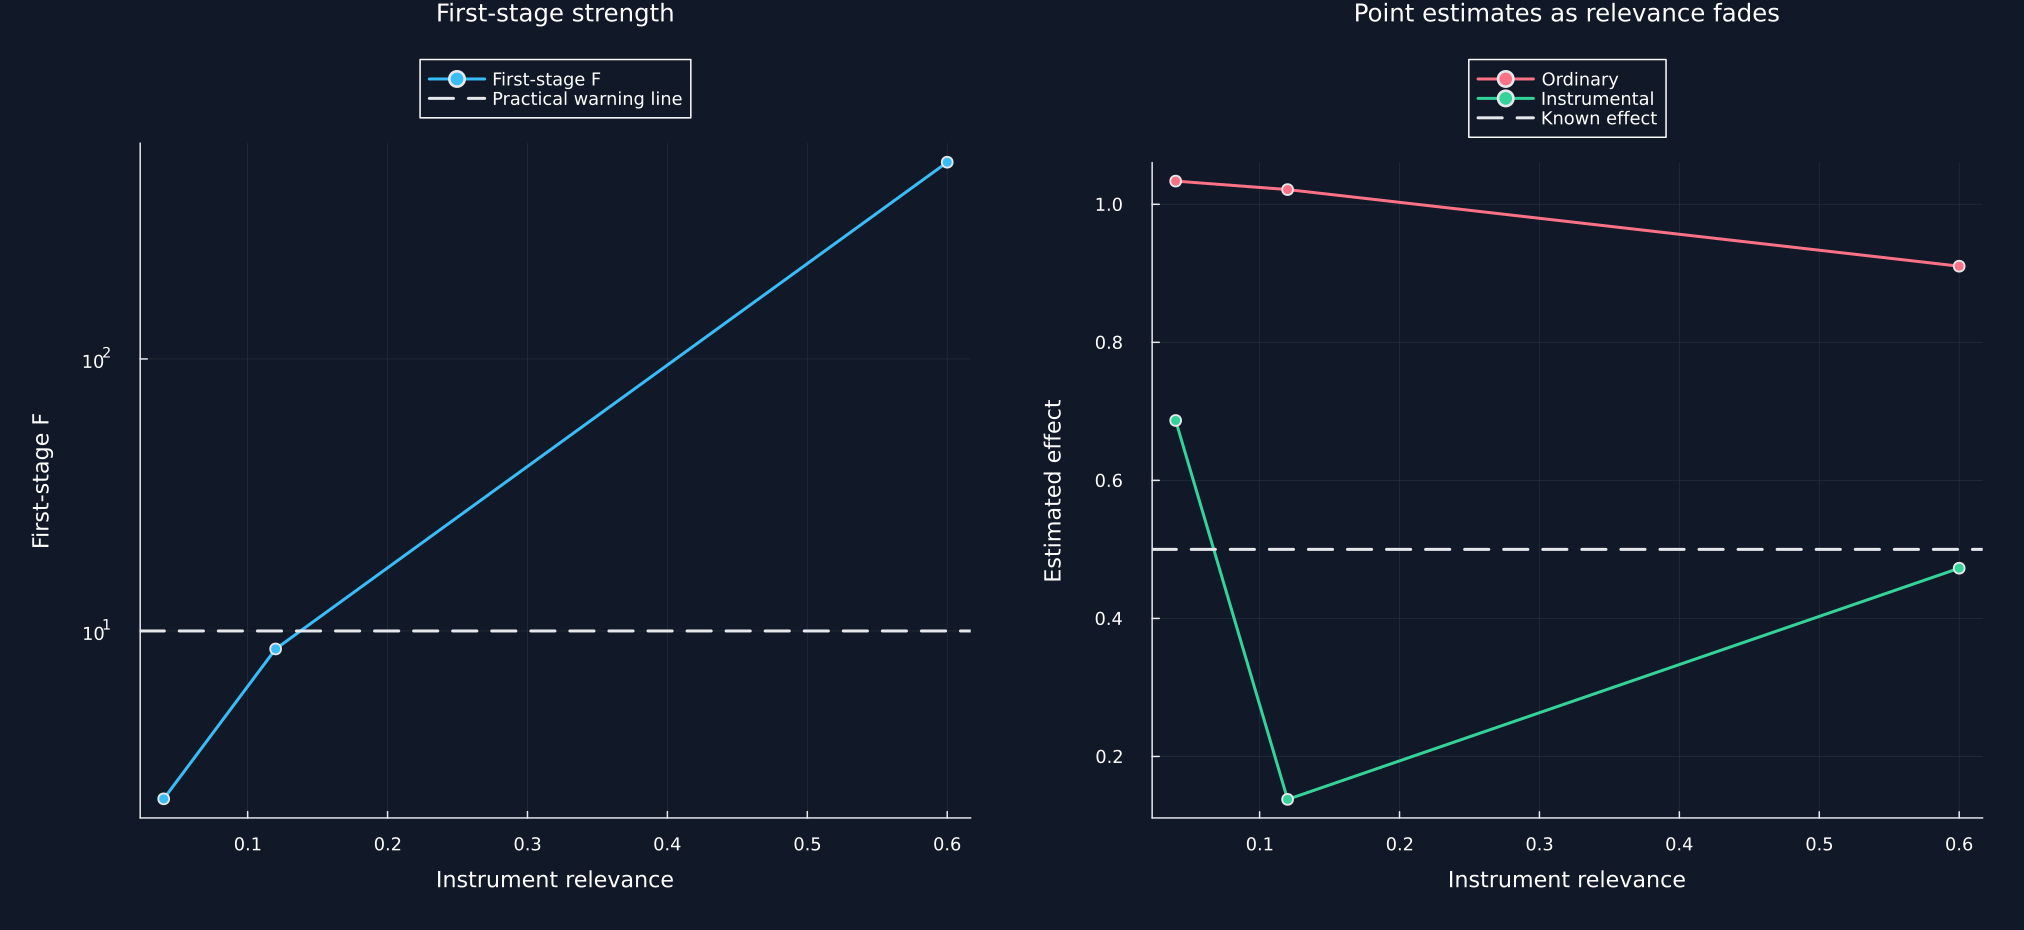

In [2]:
beta_true,phi = .5,1.
iv_parameters = frame(["Parameter","Symbol","Value"],[["Known treatment effect","beta",0.5],["Common-cause loading on treatment","phi",1.0],["Observations in released example","n",3000],["Strong-warning line","F",10],["Confidence level","one minus alpha",0.95]])
demo_rows = Tuple[]
for (index,relevance) in enumerate([.60,.12,.04])
    x,y,z,w = simulate_iv(store,"iv_demo",index;relevance)
    result = iv_wedge_analysis(x,y,z)
    wald = result.iv.wald_ci
    push!(demo_rows,(relevance,result.iv.first_stage_f,result.strong_instrument,result.ols_premium,result.iv.beta,result.wedge,wald[1],wald[2],result.ar_set.kind,result.ar_set.lo,result.ar_set.hi))
    save_data(DataFrame(Treatment=x,Outcome=y,Instrument=z,Proxy=w),paths,"iv_demo_sample_$(index)")
end
iv_demo = frame(["Instrument relevance","First-stage F","Strong by warning line","Ordinary estimate","Instrumental estimate","Wedge","Ordinary interval low","Ordinary interval high","Robust set kind","Robust set low","Robust set high"],demo_rows)
table(iv_parameters,"iv_structural_parameters","Values used in the instrumental-variable experiments.")
table(select(iv_demo,["Instrument relevance","First-stage F","Ordinary estimate","Instrumental estimate","Robust set kind"]),"iv_demo","Point estimates, strength, and robust-set shape across three instrument strengths.")
save_data(iv_demo,paths,"iv_demo_details")
strength = plot(iv_demo[!,"Instrument relevance"],iv_demo[!,"First-stage F"];marker=:circle,color=palette.cyan,label="First-stage F",yscale=:log10,xlabel="Instrument relevance",ylabel="First-stage F",title="First-stage strength",legend=:outertop)
hline!(strength,[10.];color=palette.text,linestyle=:dash,label="Practical warning line")
estimates = plot(iv_demo[!,"Instrument relevance"],iv_demo[!,"Ordinary estimate"];marker=:circle,color=palette.rose,label="Ordinary",xlabel="Instrument relevance",ylabel="Estimated effect",title="Point estimates as relevance fades",legend=:outertop)
plot!(estimates,iv_demo[!,"Instrument relevance"],iv_demo[!,"Instrumental estimate"];marker=:circle,color=palette.green,label="Instrumental")
hline!(estimates,[beta_true];color=palette.text,linestyle=:dash,label="Known effect")
save_figure(plot(strength,estimates;layout=(1,2),size=(1350,620)),paths,"iv_demo_strength")


## Recovering the effect with a strong instrument

The ordinary-versus-instrumental wedge records the absolute distance between two fitted effects:

$$
W_{\mathrm{IV}}=\left|\widehat\beta_{\mathrm{OLS}}-\widehat\beta_{\mathrm{IV}}\right|.
$$

Here, $W_{\mathrm{IV}}$ is the diagnostic wedge, $\widehat\beta_{\mathrm{OLS}}$ is the ordinary treatment slope, and $\widehat\beta_{\mathrm{IV}}$ is the instrumental-variable estimate. The wedge can reveal disagreement under a valid strong instrument, but it cannot establish exclusion or outside variation.

Row,Method,Mean estimate,Bias,Mean squared error,Repetitions
,String,Float64,Float64,Float64,Int64
1,Instrumental,0.494619,-0.00538137,0.00379269,400
2,Ordinary,1.33488,0.834885,0.697951,400
3,Noisy proxy adjustment,1.27711,0.777107,0.604781,400


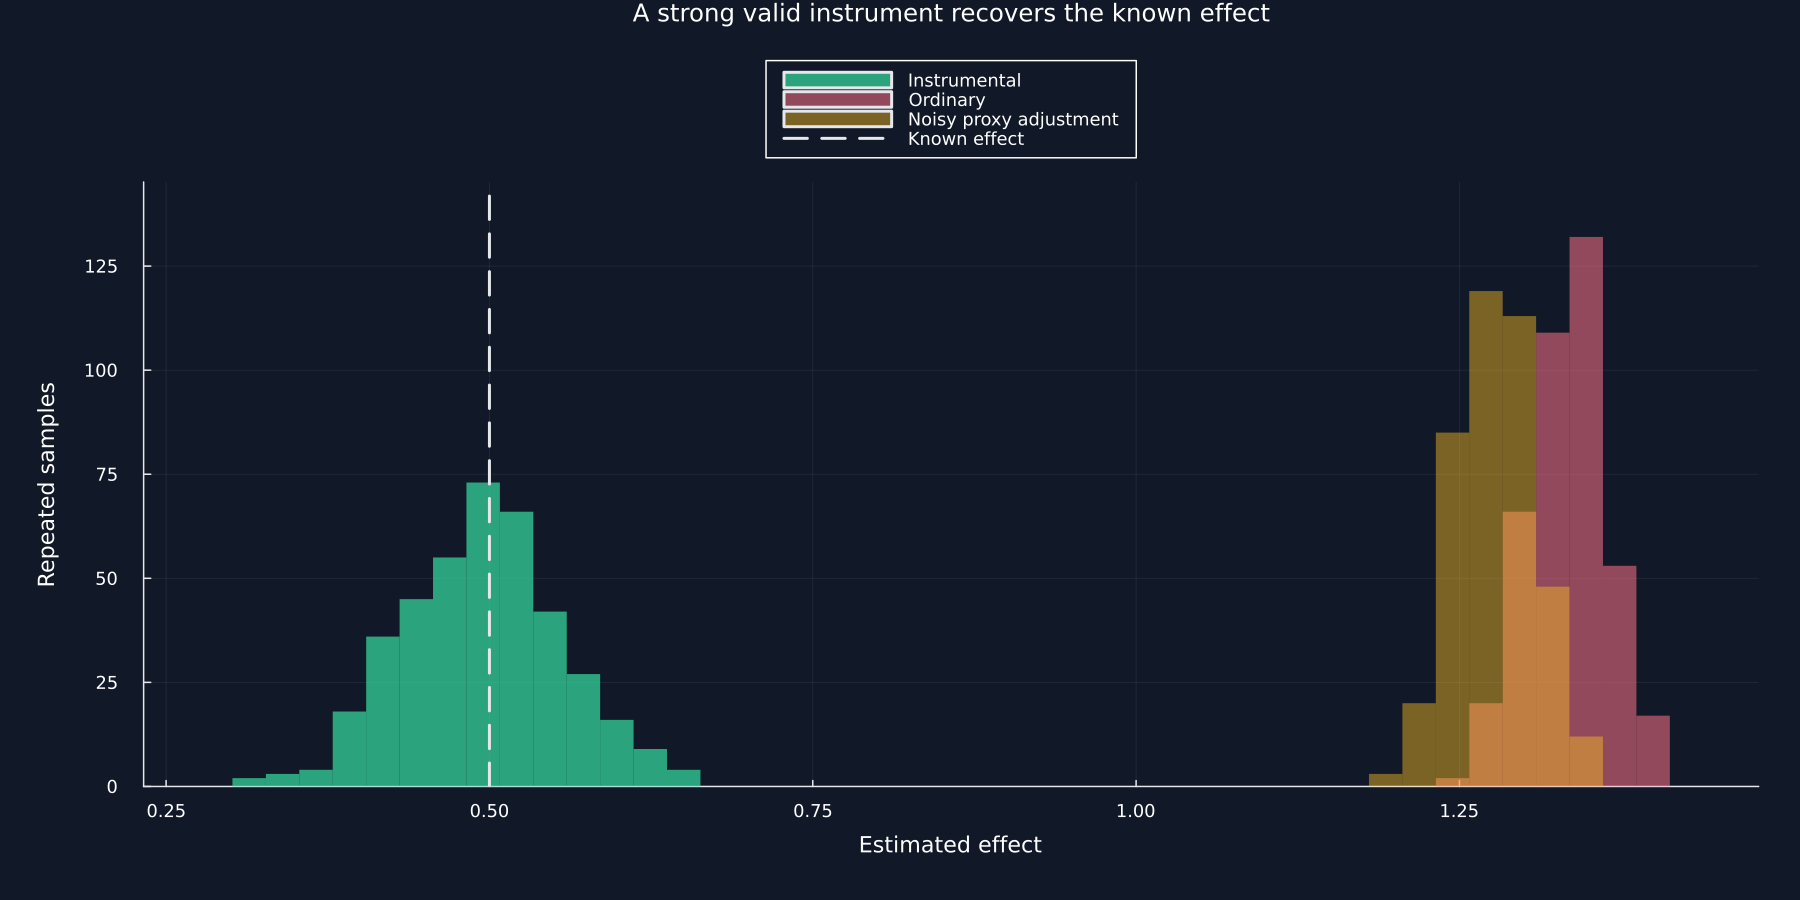

Row,Outcome common-cause loading,Mean wedge,Wedge standard deviation,Repetitions
,Float64,Float64,Float64,Int64
1,0.0,0.0146275,0.0117913,400
2,1.0,0.333846,0.0292547,400
3,2.5,0.833885,0.0560796,400


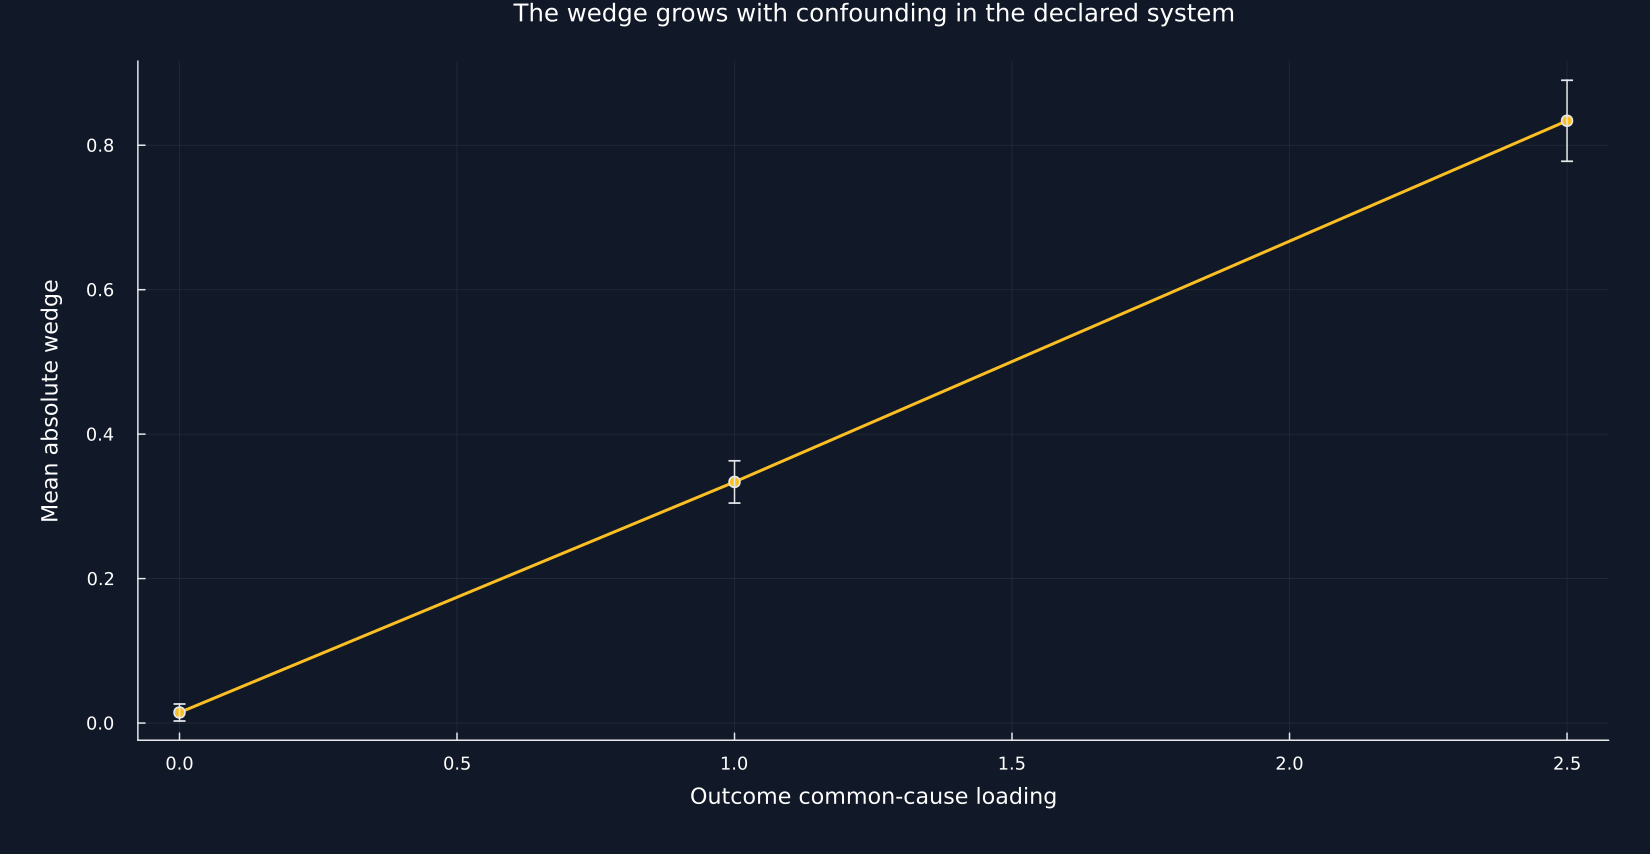

In [3]:
repetitions,observations = 400,2000
recovery_names = ["Instrumental","Ordinary","Noisy proxy adjustment"]
recovery = zeros(repetitions,3)
for repetition in 1:repetitions
    x,y,z,w = simulate_iv(store,"iv_recovery",repetition;gamma=2.5)
    recovery[repetition,1] = iv_premium(x,y,z).beta
    recovery[repetition,2] = ols_premium(x,y)
    recovery[repetition,3] = ols_slope(y,x,w)
end
strong_recovery = frame(["Method","Mean estimate","Bias","Mean squared error","Repetitions"],[(name,mean(recovery[:,index]),mean(recovery[:,index])-beta_true,mean_squared_error(recovery[:,index],beta_true),repetitions) for (index,name) in enumerate(recovery_names)])
table(strong_recovery,"iv_strong_recovery","Repeated-sample recovery with a strong valid instrument.")
save_data(DataFrame(recovery,recovery_names),paths,"iv_recovery_repetitions")
bins = range(minimum(recovery),maximum(recovery);length=44)
histogram_peak = maximum(count(value->bins[index]<=value&&(value<bins[index+1]||(index==length(bins)-1&&value==bins[index+1])),values) for values in eachcol(recovery) for index in 1:length(bins)-1)
figure = plot(;ylims=(0,1.1histogram_peak),xlabel="Estimated effect",ylabel="Repeated samples",title="A strong valid instrument recovers the known effect",legend=:outertop,size=(1200,600))
for (index,(color,opacity)) in enumerate([(palette.green,.75),(palette.rose,.55),(palette.amber,.45)])
    histogram!(figure,recovery[:,index];bins,alpha=opacity,color,linealpha=0,label=recovery_names[index])
end
vline!(figure,[beta_true];color=palette.text,linestyle=:dash,linewidth=2,label="Known effect")
save_figure(figure,paths,"iv_strong_recovery_distributions")
wedge_rows,wedge_repetitions = Tuple[],Tuple[]
for (index,gamma) in enumerate([0.,1.,2.5])
    values = zeros(repetitions)
    for repetition in 1:repetitions
        x,y,z,w = simulate_iv(store,"iv_wedge",(index-1)*repetitions+repetition;gamma)
        values[repetition] = ols_iv_wedge(x,y,z)
        push!(wedge_repetitions,(gamma,repetition-1,values[repetition]))
    end
    push!(wedge_rows,(gamma,mean(values),std(values),repetitions))
end
iv_wedge_sweep = frame(["Outcome common-cause loading","Mean wedge","Wedge standard deviation","Repetitions"],wedge_rows)
table(iv_wedge_sweep,"iv_wedge_sweep","Ordinary and instrumental-estimate disagreement as confounding increases.")
save_data(frame(["Outcome common-cause loading","Repetition","Wedge"],wedge_repetitions),paths,"iv_wedge_repetitions")
figure = plot(iv_wedge_sweep[!,"Outcome common-cause loading"],iv_wedge_sweep[!,"Mean wedge"];yerror=iv_wedge_sweep[!,"Wedge standard deviation"],marker=:circle,color=palette.amber,legend=false,xlabel="Outcome common-cause loading",ylabel="Mean absolute wedge",title="The wedge grows with confounding in the declared system",size=(1100,570))
save_figure(figure,paths,"iv_wedge_sweep")


## Anderson-Rubin Sets

The Anderson-Rubin statistic tests a proposed effect by checking whether the instrument predicts the outcome residual formed under that effect:

$$
\operatorname{AR}(b)
=\frac{\left[Z^{\mathsf T}(Y-bX)\right]^2}
{(Z^{\mathsf T}Z)\widehat{\operatorname{Var}}(Y-bX)},
\qquad
\mathcal C_{1-\alpha}=\{b:\operatorname{AR}(b)\leq\chi^2_{1,1-\alpha}\}.
$$

Here, $b$ is a proposed treatment effect, $Y-bX$ is the residual implied by that proposal, $Z$ is the demeaned instrument vector, $\widehat{\operatorname{Var}}$ is the sample residual variance, $\chi^2_{1,1-\alpha}$ is a chi-squared critical value with one degree of freedom, and $\mathcal C_{1-\alpha}$ is the confidence set containing all proposals not rejected.

Row,Relevance,Coverage,Bounded share,Median F,Point MSE,Runs
,Float64,Float64,Float64,Float64,Float64,Int64
1,1.0,0.945,1.0,1002.95,0.00365538,400
2,0.3,0.9475,1.0,89.375,0.0452214,400
3,0.1,0.945,0.8775,9.45181,10.4094,400
4,0.05,0.9225,0.33,2.55018,116.153,400


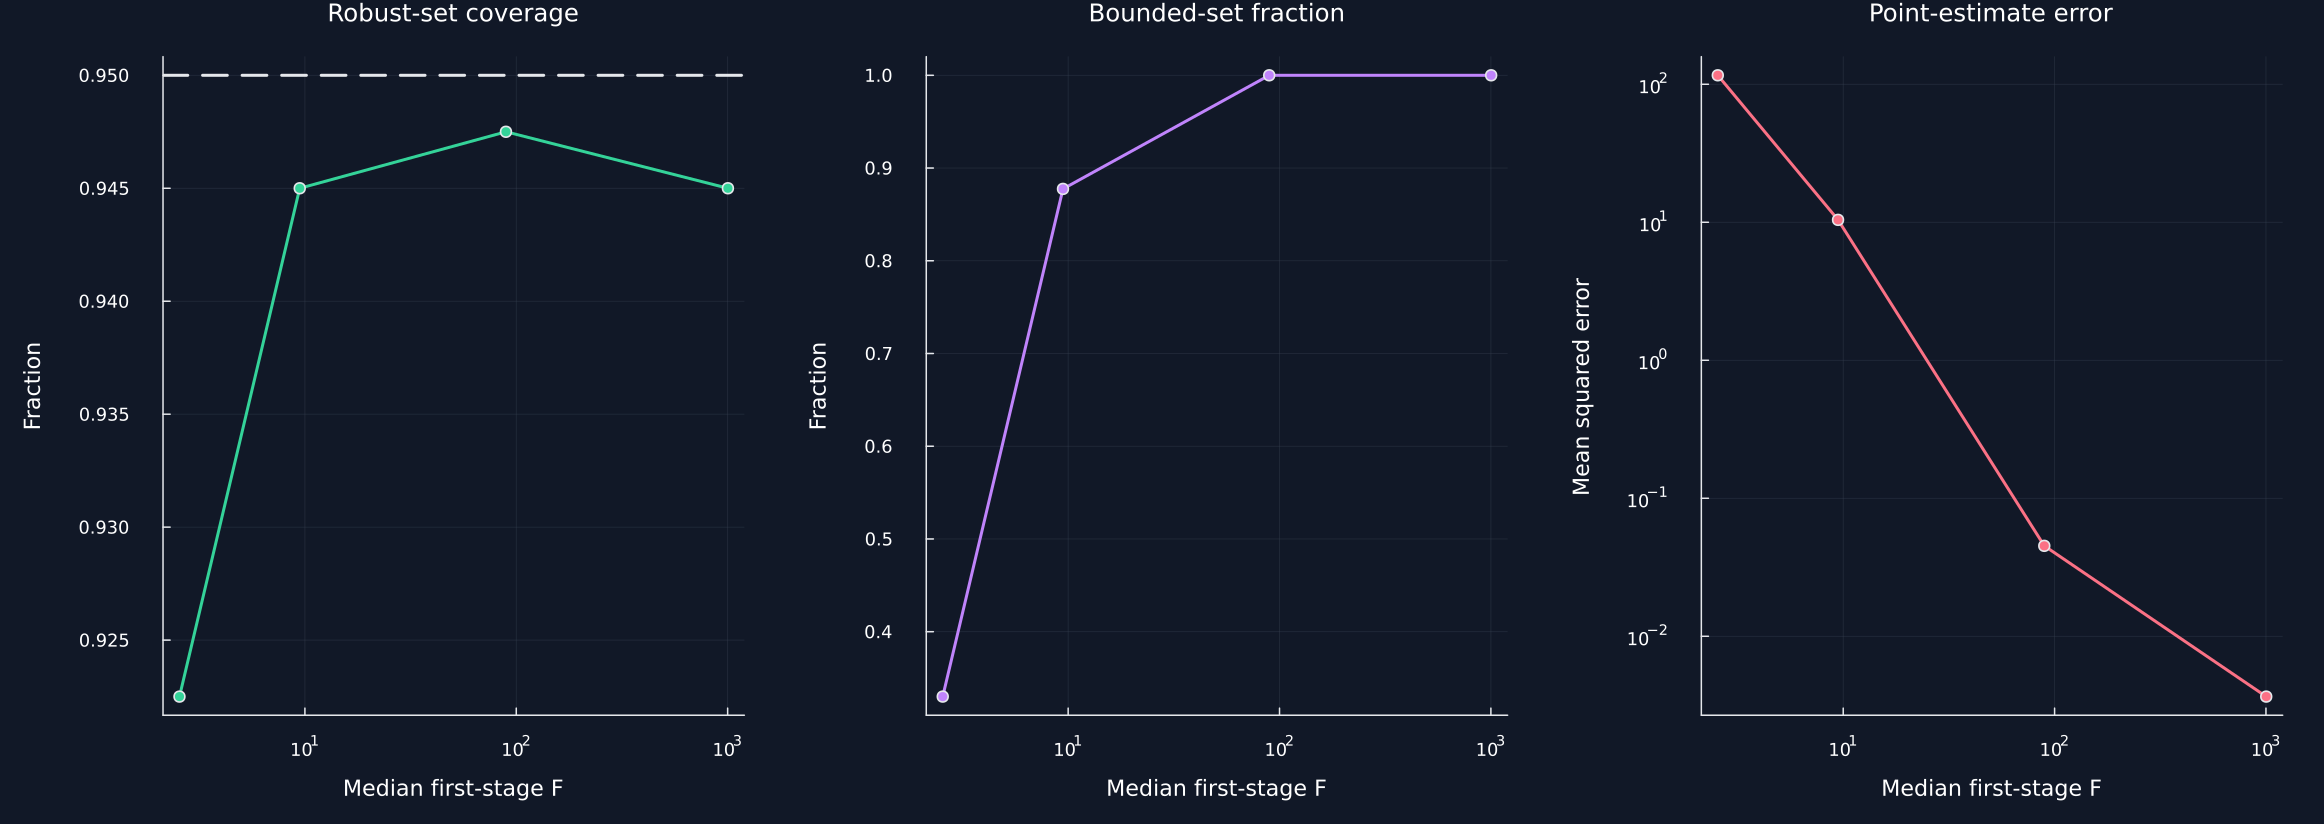

In [4]:
ar_rows,ar_repetitions = Tuple[],Tuple[]
for (index,relevance) in enumerate([1.,.3,.1,.05])
    covered,bounded = 0,0
    first_stage,points = zeros(repetitions),zeros(repetitions)
    for repetition in 1:repetitions
        x,y,z,w = simulate_iv(store,"iv_ar",(index-1)*repetitions+repetition;gamma=2.5,relevance)
        contains = in_anderson_rubin_set(beta_true,x,y,z)
        robust_set = anderson_rubin_set(x,y,z)
        point = iv_premium(x,y,z)
        covered += contains
        bounded += robust_set.bounded
        first_stage[repetition],points[repetition] = point.first_stage_f,point.beta
        push!(ar_repetitions,(relevance,repetition-1,contains,robust_set.kind,robust_set.lo,robust_set.hi,robust_set.bounded,point.first_stage_f,point.beta,point.wald_ci[1],point.wald_ci[2]))
    end
    push!(ar_rows,(relevance,covered/repetitions,bounded/repetitions,median(first_stage),mean_squared_error(points,beta_true),repetitions))
end
ar_sweep = frame(["Instrument relevance","Robust-set coverage","Bounded-set fraction","Median first-stage F","Point-estimate mean squared error","Repetitions"],ar_rows)
ar_sweep_book = rename(ar_sweep,["Relevance","Coverage","Bounded share","Median F","Point MSE","Runs"])
table(ar_sweep_book,"iv_ar_sweep","Coverage, informativeness, and point error across instrument strength.")
save_data(frame(["Instrument relevance","Repetition","Contains known effect","Set kind","Lower end","Upper end","Bounded","First-stage F","Point estimate","Wald low","Wald high"],ar_repetitions),paths,"iv_ar_repetitions")
panels = Plots.Plot[]
for (column,title,color) in [("Robust-set coverage","Robust-set coverage",palette.green),("Bounded-set fraction","Bounded-set fraction",violet),("Point-estimate mean squared error","Point-estimate error",palette.rose)]
    panel = plot(ar_sweep[!,"Median first-stage F"],ar_sweep[!,column];marker=:circle,color,label="",xscale=:log10,xlabel="Median first-stage F",ylabel=column=="Point-estimate mean squared error" ? "Mean squared error" : "Fraction",title,legend=false)
    column=="Point-estimate mean squared error" && plot!(panel;yscale=:log10)
    column=="Robust-set coverage" && hline!(panel,[.95];color=palette.text,linestyle=:dash,label="")
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,3),size=(1550,550)),paths,"iv_ar_sweep")


### Understanding confidence-set limits

A confidence set becomes uninformative when it contains all sufficiently extreme candidates or the whole real line:

$$
\mathcal C_{1-\alpha}\in\{[\ell,u],\ (-\infty,u],\ [\ell,\infty),\ (-\infty,\ell]\cup[u,\infty),\ \mathbb R\}.
$$

Here, $[\ell,u]$ is a bounded interval, the next two sets are rays, the fourth is a union of two rays, and $\mathbb R$ is the whole real line. An unbounded result keeps the uncertainty visible instead of forcing a precise point.

Row,Case,Mean estimate,Mean squared error,Repetitions
,String,Float64,Float64,Int64
1,Instrumental without confounding,0.499269,0.000474129,400
2,Ordinary without confounding,0.500087,0.000164943,400
3,Instrumental with measured common cause,0.502563,0.00385857,400
4,Measured-common-cause adjustment,0.49975,0.000233043,400


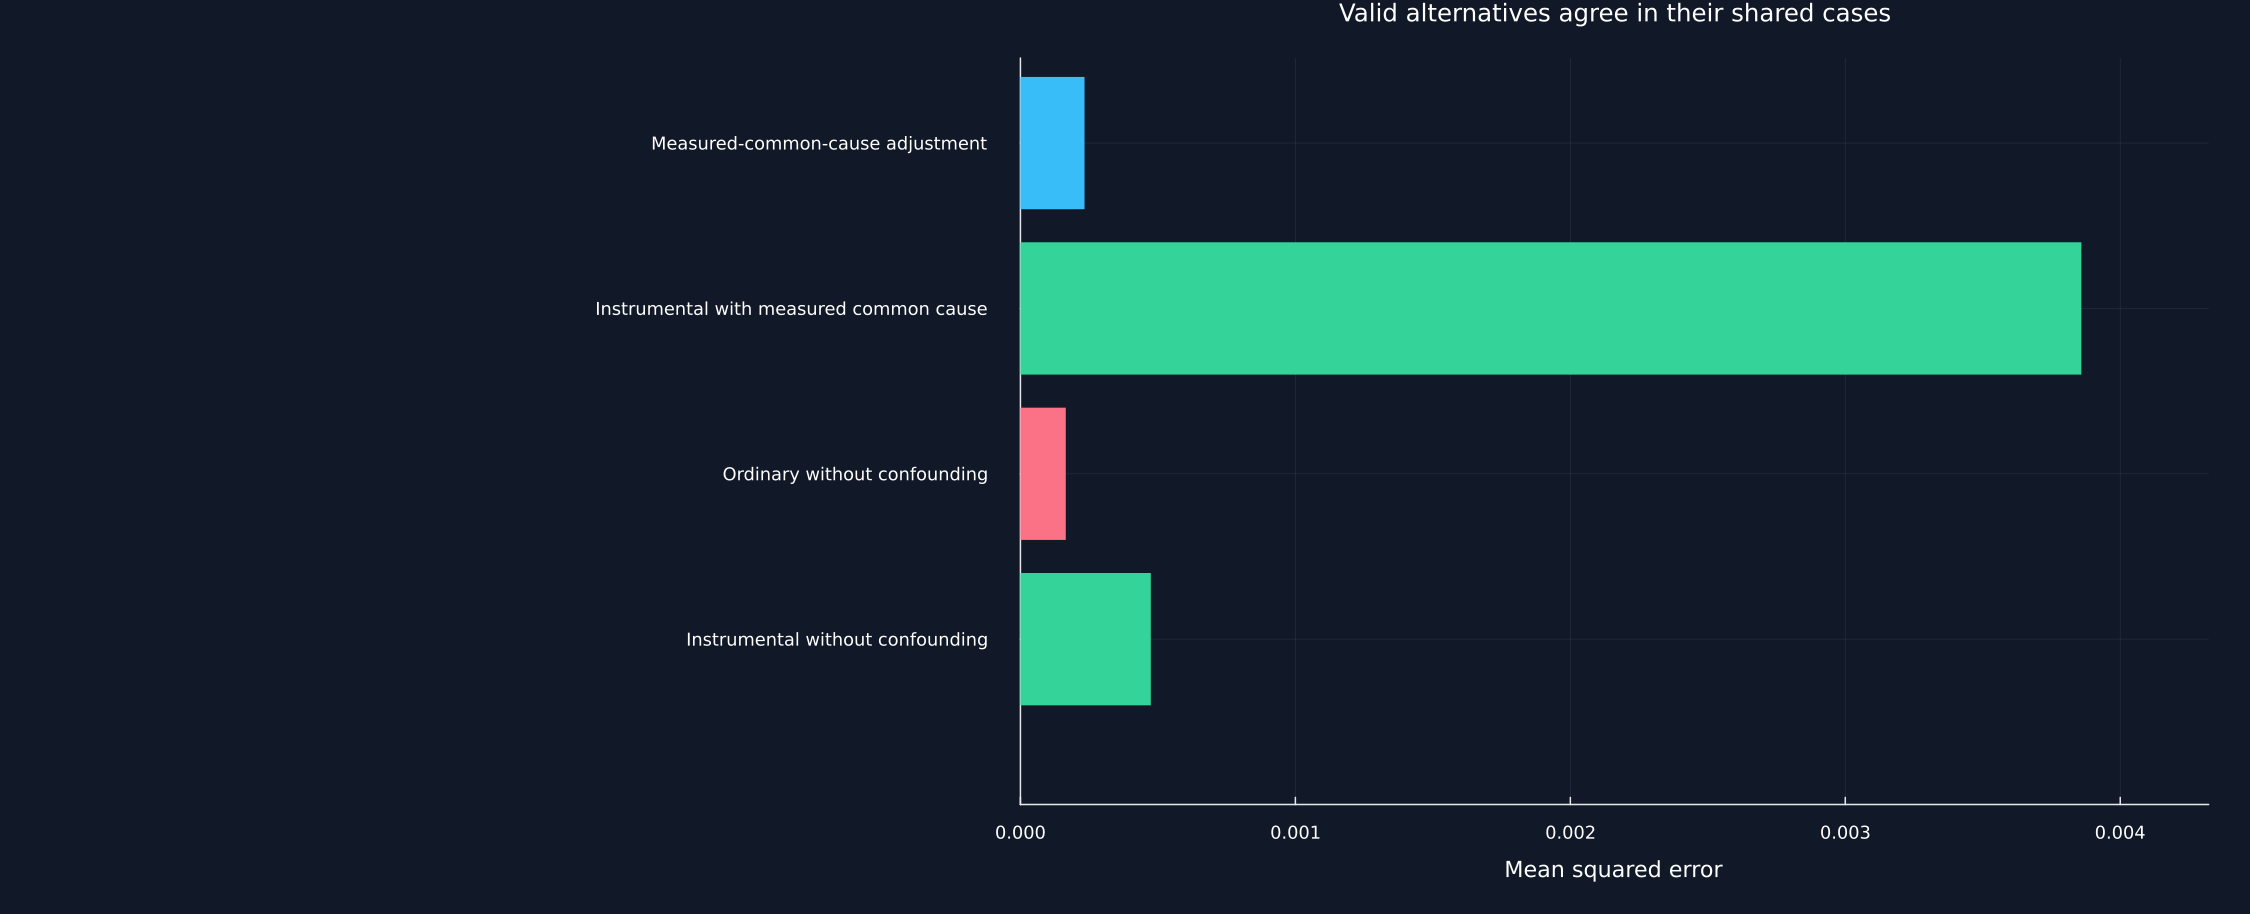

Row,Case,First-stage F,Set kind,Lower end,Upper end,Contains known effect
,String,Float64,String,Float64,Float64,String
1,Strong instrument,1917.14,interval,0.408184,0.577115,Yes
2,Near-irrelevant instrument,0.0656274,allreal,-Inf,Inf,Yes


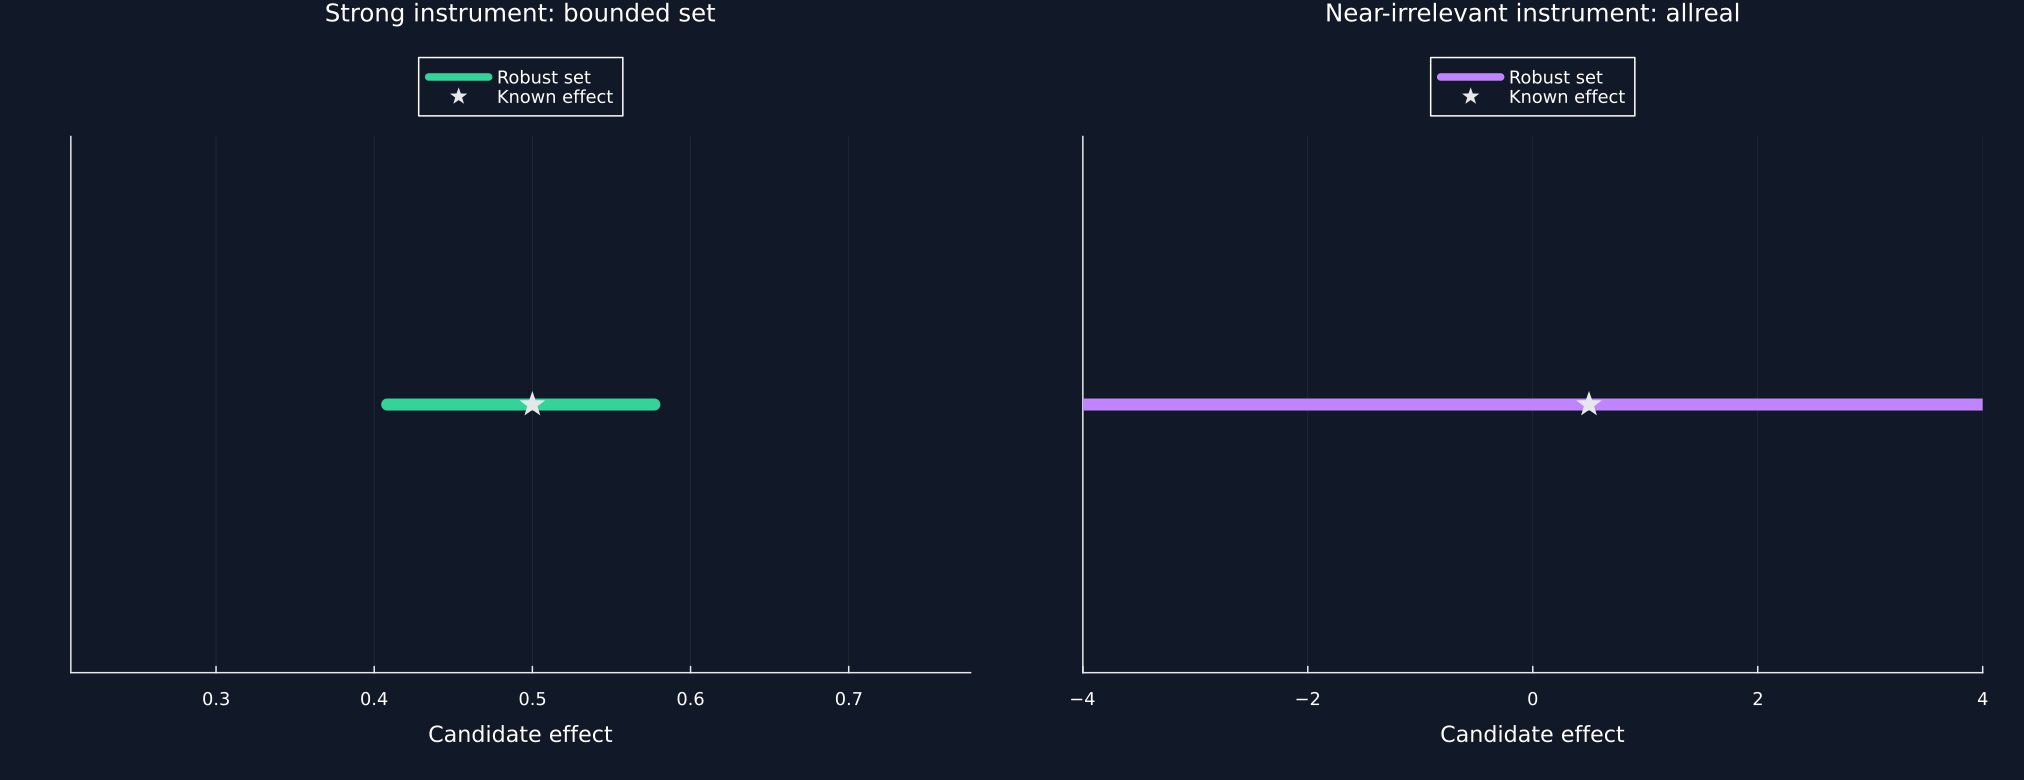

In [5]:
limiting_names = ["Instrumental without confounding","Ordinary without confounding","Instrumental with measured common cause","Measured-common-cause adjustment"]
limiting_values = zeros(repetitions,4)
for repetition in 1:repetitions
    x,y,z,w = simulate_iv(store,"iv_limiting",2repetition-1;gamma=0.)
    limiting_values[repetition,1] = iv_premium(x,y,z).beta
    limiting_values[repetition,2] = ols_premium(x,y)
    xm,ym,zm,wm = simulate_iv(store,"iv_limiting",2repetition;gamma=2.5,proxy_noise=0.)
    limiting_values[repetition,3] = iv_premium(xm,ym,zm).beta
    limiting_values[repetition,4] = ols_slope(ym,xm,wm)
end
limiting_cases = frame(["Case","Mean estimate","Mean squared error","Repetitions"],[(name,mean(limiting_values[:,index]),mean_squared_error(limiting_values[:,index],beta_true),repetitions) for (index,name) in enumerate(limiting_names)])
table(limiting_cases,"iv_limiting_cases","Limiting comparisons with no confounding or a measured common cause.")
save_data(DataFrame(limiting_values,limiting_names),paths,"iv_limiting_repetitions")
figure = bar(1:4,limiting_cases[!,"Mean squared error"];orientation=:horizontal,color=[palette.green,palette.rose,palette.green,palette.cyan],linealpha=0,legend=false,yticks=(1:4,limiting_names),xlims=(0,1.12maximum(limiting_cases[!,"Mean squared error"])),xlabel="Mean squared error",title="Valid alternatives agree in their shared cases",left_margin=100Plots.mm,size=(1500,610))
save_figure(figure,paths,"iv_limiting_cases")
xs,ys,zs,ws = simulate_iv(store,"iv_sets",1;gamma=2.5)
xw,yw,zw,ww = simulate_iv(store,"iv_sets",2;gamma=2.5,relevance=.01)
strong_set,weak_set = anderson_rubin_set(xs,ys,zs),anderson_rubin_set(xw,yw,zw)
set_examples = frame(["Case","First-stage F","Set kind","Lower end","Upper end","Bounded","Contains known effect"],[(name,iv_premium(x,y,z).first_stage_f,set.kind,set.lo,set.hi,set.bounded,in_anderson_rubin_set(beta_true,x,y,z)) for (name,x,y,z,set) in [("Strong instrument",xs,ys,zs,strong_set),("Near-irrelevant instrument",xw,yw,zw,weak_set)]])
table(select(set_examples,["Case","First-stage F","Set kind","Lower end","Upper end","Contains known effect"]),"iv_set_examples","Robust-set shapes for a strong and a near-irrelevant instrument.")
save_data(set_examples,paths,"iv_set_details")
strong_panel = plot([strong_set.lo,strong_set.hi],[0.,0.];color=palette.green,linewidth=8,label="Robust set",xlims=(strong_set.lo-.2,strong_set.hi+.2),ylims=(-.5,.5),yticks=[],xlabel="Candidate effect",title="Strong instrument: bounded set",legend=:outertop)
scatter!(strong_panel,[beta_true],[0.];color=palette.text,markershape=:star5,markersize=9,label="Known effect")
weak_panel = plot([-4.,4.],[0.,0.];color=violet,linewidth=8,label="Robust set",xlims=(-4,4),ylims=(-.5,.5),yticks=[],xlabel="Candidate effect",title="Near-irrelevant instrument: "*weak_set.kind,legend=:outertop)
scatter!(weak_panel,[beta_true],[0.];color=palette.text,markershape=:star5,markersize=9,label="Known effect")
save_figure(plot(strong_panel,weak_panel;layout=(1,2),size=(1350,520)),paths,"iv_set_examples")


## Local Effects for Compliers

With a binary instrument and monotone treatment response, the Wald ratio identifies the average effect for people whose treatment changes with the instrument:

$$
\beta_{\mathrm{LATE}}
=\frac{\mathbb E[Y\mid Z=1]-\mathbb E[Y\mid Z=0]}
{\mathbb E[X\mid Z=1]-\mathbb E[X\mid Z=0]}
=\mathbb E[Y(1)-Y(0)\mid X(1)>X(0)].
$$

Here, $Z\in\{0,1\}$ is the assigned instrument, $X(z)$ is potential treatment under assignment $z$, $Y(1)-Y(0)$ is the individual treatment effect, and the condition $X(1)>X(0)$ selects compliers. The result is local to that group and need not equal the population average effect.

Row,Group,Share,Treatment under instrument 0,Treatment under instrument 1,Group treatment effect
,String,Float64,Float64,Float64,Float64
1,Never treated,0.19742,0.0,0.0,0.2
2,Complier,0.60148,0.0,1.0,0.8
3,Always treated,0.2011,1.0,1.0,2.4


Row,Quantity,Value
,String,Float64
1,First-stage treatment change,0.602646
2,Reduced-form outcome change,0.468608
3,Wald ratio,0.777583
4,Known complier average effect,0.8
5,Known population average effect,1.00331


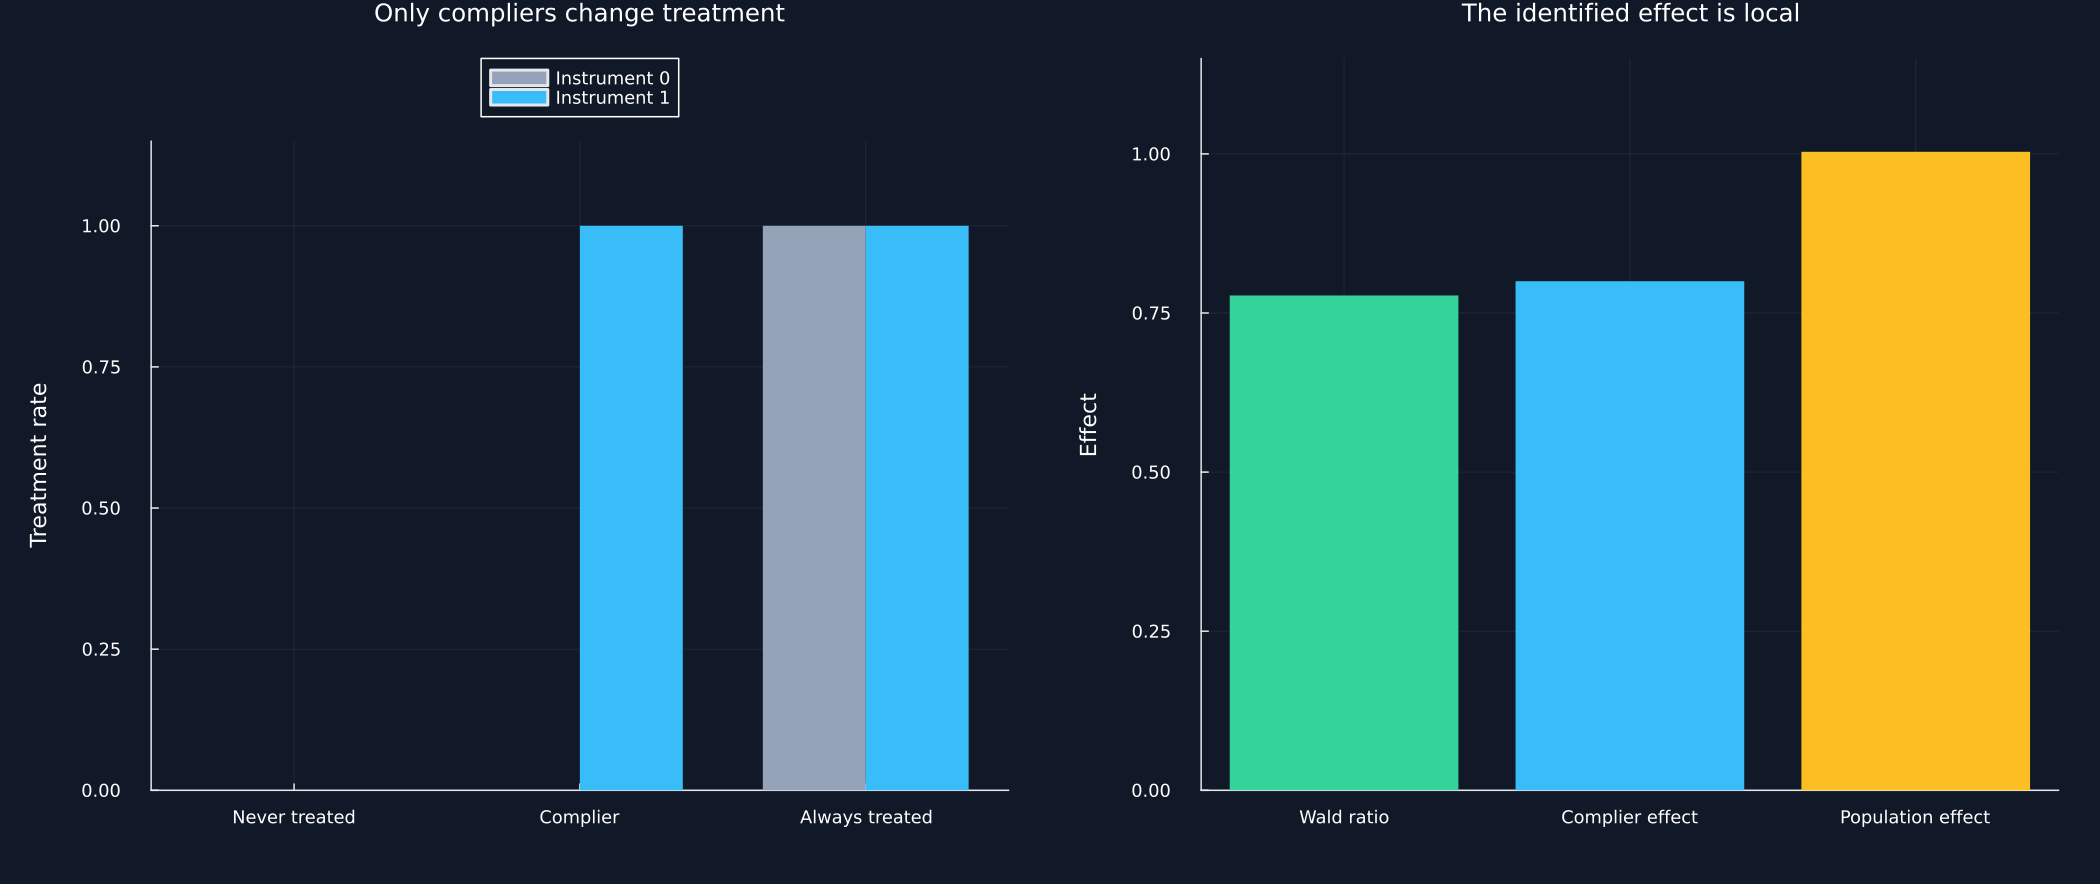

In [6]:
compliance_n = 100000
compliance_specification = TOML.parsefile(joinpath(input_directory,"iv_inputs.toml"))["compliance"]
compliance_path = joinpath(input_directory,compliance_specification["name"])
compliance_primitives = reshape(read!(compliance_path,Vector{Float64}(undef,compliance_n*3)),compliance_n,3)
types = [value<.20 ? "Never treated" : value<.80 ? "Complier" : "Always treated" for value in compliance_primitives[:,1]]
instrument = Int.(compliance_primitives[:,2])
treatment_zero = Int.(types.=="Always treated")
treatment_one = Int.(types.!= "Never treated")
treatment_values = ifelse.(instrument.==1,treatment_one,treatment_zero)
type_effect = [name=="Never treated" ? .2 : name=="Complier" ? .8 : 2.4 for name in types]
baseline = compliance_primitives[:,3]
outcome_values = baseline+type_effect.*treatment_values
reduced_form = mean(outcome_values[instrument.==1])-mean(outcome_values[instrument.==0])
first_stage = mean(treatment_values[instrument.==1])-mean(treatment_values[instrument.==0])
wald_effect = reduced_form/first_stage
complier_effect,population_effect = mean(type_effect[types.=="Complier"]),mean(type_effect)
compliance_types = frame(["Group","Share","Treatment under instrument 0","Treatment under instrument 1","Group treatment effect"],[(name,mean(types.==name),mean(treatment_zero[types.==name]),mean(treatment_one[types.==name]),mean(type_effect[types.==name])) for name in ["Never treated","Complier","Always treated"]])
late_comparison = DataFrame("Quantity"=>["First-stage treatment change","Reduced-form outcome change","Wald ratio","Known complier average effect","Known population average effect"],"Value"=>[first_stage,reduced_form,wald_effect,complier_effect,population_effect])
table(compliance_types,"iv_compliance_types","Treatment response and effect by compliance group.")
table(late_comparison,"iv_late_comparison","Wald ratio, complier effect, and population effect in a binary experiment.")
save_data(DataFrame("Group"=>types,"Instrument"=>instrument,"Treatment under instrument 0"=>treatment_zero,"Treatment under instrument 1"=>treatment_one,"Treatment"=>treatment_values,"Treatment effect"=>type_effect,"Outcome"=>outcome_values),paths,"iv_compliance_sample")
treatments = bar((1:3).- .18,compliance_types[!,"Treatment under instrument 0"];bar_width=.36,color=muted,linealpha=0,label="Instrument 0",xticks=(1:3,["Never treated","Complier","Always treated"]),xlims=(.5,3.5),ylims=(0,1.15),ylabel="Treatment rate",title="Only compliers change treatment",legend=:outertop)
bar!(treatments,(1:3).+ .18,compliance_types[!,"Treatment under instrument 1"];bar_width=.36,color=palette.cyan,linealpha=0,label="Instrument 1")
effects = bar(1:3,[wald_effect,complier_effect,population_effect];color=[palette.green,palette.cyan,palette.amber],linealpha=0,xticks=(1:3,["Wald ratio","Complier effect","Population effect"]),xlims=(.5,3.5),ylims=(0,1.15),ylabel="Effect",title="The identified effect is local",legend=false)
save_figure(plot(treatments,effects;layout=(1,2),size=(1400,590)),paths,"iv_compliance_types")


## Checking the method contract at its limits

In [7]:
zero = zeros(10)
contract_checks = frame(["Check","Expected result","Observed result","Passed"],[contract_result("Unequal lengths",()->iv_premium(zeros(9),zero,zero),DimensionMismatch),contract_result("Too few observations",()->iv_premium(zeros(2),zeros(2),zeros(2)),ArgumentError),contract_result("Invalid confidence level",()->anderson_rubin_set(zero,zero,zero,1.5),ArgumentError),contract_result("Two-dimensional treatment",()->ols_iv_wedge(zeros(10,2),zero,zero),ArgumentError)])
iv_summary = frame(["Question","Answer"],[["Does a large first-stage F prove validity?","No"],["Is 10 a theorem?","No, it is a practical warning line"],["Should a weak-instrument point be read alone?","No"],["Can the robust set be unbounded?","Yes"],["Is the binary-treatment effect universal?","No, it is local to compliers under the assumptions"]])
table(contract_checks,"iv_contract_checks","Input checks for the released instrumental-variable calculations.")
table(iv_summary,"iv_section_summary","Main conclusions from the instrumental-variable experiments.")


Row,Check,Expected result,Observed result,Passed
,String,String,String,String
1,Unequal lengths,Rejected,Rejected,Yes
2,Too few observations,Rejected,Rejected,Yes
3,Invalid confidence level,Rejected,Rejected,Yes
4,Two-dimensional treatment,Rejected,Rejected,Yes


Row,Question,Answer
,String,String
1,Does a large first-stage F prove validity?,No
2,Is 10 a theorem?,"No, it is a practical warning line"
3,Should a weak-instrument point be read alone?,No
4,Can the robust set be unbounded?,Yes
5,Is the binary-treatment effect universal?,"No, it is local to compliers under the assumptions"


## Tests

In [8]:
@assert strong_recovery[1,"Mean squared error"]<=.05
@assert strong_recovery[2,"Mean squared error"]>=.30
@assert strong_recovery[3,"Mean squared error"]>=.30
@assert issorted(iv_wedge_sweep[!,"Mean wedge"])
@assert all(.90 .<= ar_sweep[!,"Robust-set coverage"] .<= .99)
@assert ar_sweep[1,"Bounded-set fraction"]>=.98
@assert ar_sweep[end,"Bounded-set fraction"]<=.60
@assert ar_sweep[end,"Point-estimate mean squared error"]>=20.
@assert maximum(limiting_cases[!,"Mean squared error"])<=.02
@assert strong_set.bounded && !weak_set.bounded
@assert abs(wald_effect-complier_effect)<.03
@assert abs(wald_effect-population_effect)>.10
@assert all(contract_checks.Passed)
assert_artifacts(["iv_graph","iv_demo_strength","iv_strong_recovery_distributions","iv_wedge_sweep","iv_ar_sweep","iv_limiting_cases","iv_set_examples","iv_compliance_types"],["iv_conditions","iv_structural_parameters","iv_demo","iv_strong_recovery","iv_wedge_sweep","iv_ar_sweep","iv_limiting_cases","iv_set_examples","iv_compliance_types","iv_late_comparison","iv_contract_checks","iv_section_summary"])
nothing
